#### Análisis y Procesamiento de Señales

# TS3: Análisis de Fourier: FFT, desparramo, interpolación y ventaneo.
#### Juan Martucci

# Análisis Y Resultados

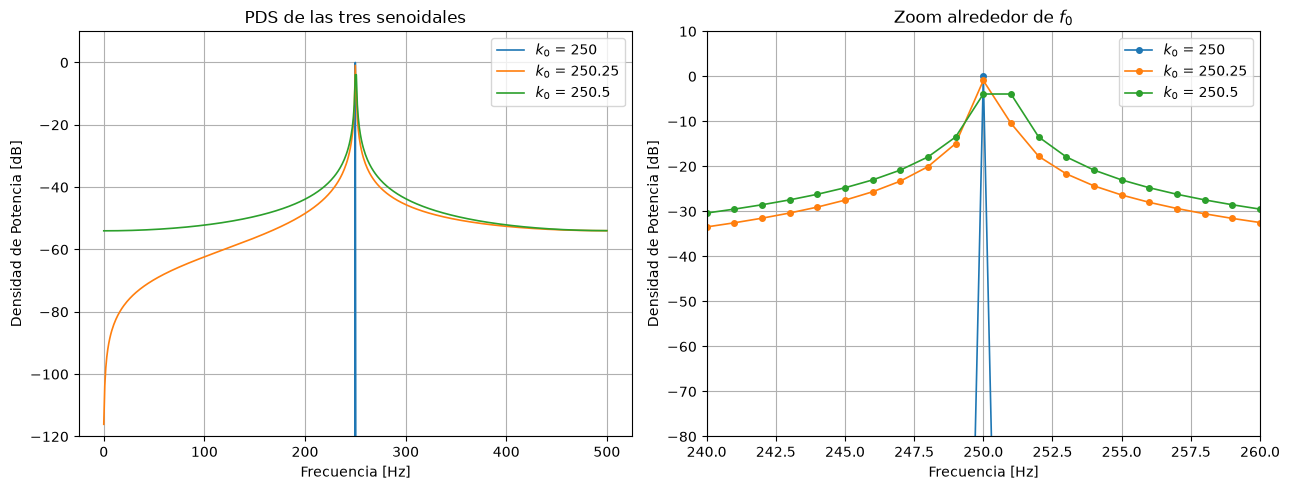

        k0      f0 [Hz]      pico [dB]   pot. en 3 bins
    250.00       250.00           0.00           1.0000
    250.25       250.25          -0.92           0.9320
    250.50       250.50          -3.92           0.8556

        k0         P tiempo     P frecuencia       error rel.
    250.00         1.000000         1.000000         0.00e+00
    250.25         0.999000         0.999000         0.00e+00
    250.50         1.000000         1.000000         0.00e+00


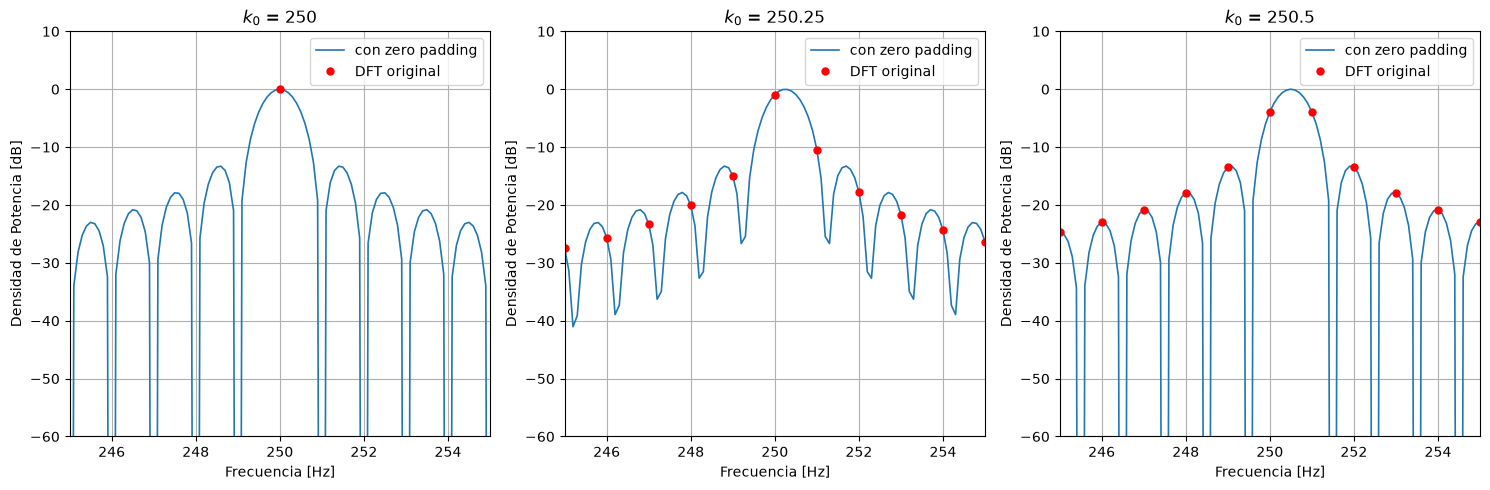


        k0      pico [dB]      f pico [Hz]     P frecuencia
    250.00           0.00           250.00         1.000000
    250.25          -0.04           250.20         0.999000
    250.50           0.00           250.50         1.000000


In [1]:
# -*- coding: utf-8 -*-
import numpy as np
import matplotlib.pyplot as plt

# Parámetros generales

N  = 1000
fs = 1000

df = fs/N

frecs = np.arange(N)*df
bfrec = frecs <= fs/2

k0s = [N/4, N/4 + 0.25, N/4 + 0.5]


def mi_funcion_sen(Vmax=1, dc=0, ff=1, ph=0, nn=N, fs=fs):
    deltaf = fs/nn
    Ts = 1/(nn*deltaf)
    tt = np.arange(0, stop=nn*Ts, step=Ts)
    xx = Vmax*np.sin(2*np.pi*ff*tt + ph) + dc
    return tt, xx


def psd(xx, nn=N):
    # densidad de potencia por bin de ancho df, normalizada con las nn
    # muestras con señal (los ceros del padding no se cuentan)
    return np.abs(np.fft.fft(xx)/nn)**2


def psd_db(xx, nn=N):
    return 10*np.log10(2*psd(xx, nn) + 1e-30)


# a) las tres senoidales de potencia unitaria

xxs = []
for k0 in k0s:
    tt, xx = mi_funcion_sen(Vmax=np.sqrt(2), ff=k0*df)
    xxs.append(xx)

fig, axs = plt.subplots(1, 2, figsize=(13, 5))

for k0, xx in zip(k0s, xxs):
    axs[0].plot(frecs[bfrec], psd_db(xx)[bfrec], lw=1.2,
                label='$k_0$ = {:g}'.format(k0))
    axs[1].plot(frecs[bfrec], psd_db(xx)[bfrec], 'o-', ms=4, lw=1.2,
                label='$k_0$ = {:g}'.format(k0))

axs[0].set_title('PDS de las tres senoidales')
axs[0].set_xlabel('Frecuencia [Hz]')
axs[0].set_ylabel('Densidad de Potencia [dB]')
axs[0].set_ylim([-120, 10])
axs[0].grid(True)
axs[0].legend()

axs[1].set_title('Zoom alrededor de $f_0$')
axs[1].set_xlabel('Frecuencia [Hz]')
axs[1].set_ylabel('Densidad de Potencia [dB]')
axs[1].set_xlim([240, 260])
axs[1].set_ylim([-80, 10])
axs[1].grid(True)
axs[1].legend()

plt.tight_layout()
plt.show()

print('{:>10} {:>12} {:>14} {:>16}'.format('k0', 'f0 [Hz]', 'pico [dB]', 'pot. en 3 bins'))
for k0, xx in zip(k0s, xxs):
    PP = psd(xx)
    kk = int(round(k0))
    p3 = 2*np.sum(PP[kk-1:kk+2])
    print('{:10.2f} {:12.2f} {:14.2f} {:16.4f}'.format(
        k0, k0*df, 10*np.log10(2*np.max(PP)), p3))


# b) identidad de Parseval

print('')
print('{:>10} {:>16} {:>16} {:>16}'.format('k0', 'P tiempo', 'P frecuencia', 'error rel.'))
for k0, xx in zip(k0s, xxs):
    Pt = np.mean(xx**2)
    Pf = np.sum(psd(xx))
    print('{:10.2f} {:16.6f} {:16.6f} {:16.2e}'.format(k0, Pt, Pf, abs(Pt-Pf)/Pt))


# c) zero padding: 9*N ceros al final

M = 10*N
frecs_pad = np.arange(M)*fs/M
bfrec_pad = frecs_pad <= fs/2

fig, axs = plt.subplots(1, 3, figsize=(15, 5))

for jj, (k0, xx) in enumerate(zip(k0s, xxs)):

    xx_pad = np.concatenate((xx, np.zeros(9*N)))

    axs[jj].plot(frecs_pad[bfrec_pad], psd_db(xx_pad)[bfrec_pad], lw=1.2,
                 label='con zero padding')
    axs[jj].plot(frecs[bfrec], psd_db(xx)[bfrec], 'ro', ms=5,
                 label='DFT original')
    axs[jj].set_title('$k_0$ = {:g}'.format(k0))
    axs[jj].set_xlabel('Frecuencia [Hz]')
    axs[jj].set_ylabel('Densidad de Potencia [dB]')
    axs[jj].set_xlim([245, 255])
    axs[jj].set_ylim([-60, 10])
    axs[jj].grid(True)
    axs[jj].legend()

plt.tight_layout()
plt.show()


print('')
print('{:>10} {:>14} {:>16} {:>16}'.format('k0', 'pico [dB]', 'f pico [Hz]', 'P frecuencia'))
for k0, xx in zip(k0s, xxs):
    xx_pad = np.concatenate((xx, np.zeros(9*N)))
    PP = psd(xx_pad)
    Pf = np.sum(PP)*N/M
    kk = np.argmax(PP[bfrec_pad])
    print('{:10.2f} {:14.2f} {:16.2f} {:16.6f}'.format(
        k0, 10*np.log10(2*PP[kk]), frecs_pad[kk], Pf))

## Conclusión

**a)** Con k0 = 250 la senoidal entra con un número entero de ciclos en la
ventana, así que toda la potencia cae en dos bins y el pico da 0.00 dB, con el
resto del espectro numéricamente nulo. Basta correr la frecuencia 0.25 o 0.5 Hz
para que el espectro cambie por completo: aparece energía en todos los bins y el
pico baja 0.92 y 3.92 dB. Este último valor es el peor caso posible, que se da
con media desintonía y vale 20*log10(2/pi). Sumando los tres bins centrales
queda el 100%, el 93.2% y el 85.6% de la potencia, el resto quedó desparramado
por toda la banda.

**b)** Parseval se verifica en los tres casos: la potencia calculada en el
tiempo y la suma de la PDS dan el mismo número, con error relativo nulo. Lo que
cambia de un caso a otro es ese número: para k0 = 250 y 250.5 da 1, y para
k0 = 250.25 da 0.999, porque ahí 2*f0 no cae en la grilla y la varianza muestral
no es exactamente A^2/2. La identidad igual se cumple, los dos lados dan 0.999.
La desintonía entonces no cambia la potencia, solamente la reparte distinto
entre los bins.

La explicación del fenómeno es que la DFT no analiza la senoidal infinita sino
el producto de esa senoidal por una ventana rectangular de N muestras. En
frecuencia eso equivale a convolucionar las dos deltas con el kernel de
Dirichlet, cuyos ceros están espaciados exactamente df, y recién después
muestrear esa DTFT en los múltiplos de df. Si f0 es múltiplo de df los ceros del
kernel caen justo sobre todos los bins vecinos y el espectro se ve limpio; si no
lo es, se muestrea entre los ceros y aparece el desparramo. O sea que el
espectro continuo es prácticamente el mismo en los tres casos, lo que cambia es
dónde lo muestrea la grilla.

**c)** Con los 9*N ceros la grilla pasa a 10000 puntos y el delta f ficticio a
0.1 Hz. En las figuras la DFT original cae exactamente sobre la curva
interpolada cada 10 muestras, lo que confirma que el padding no agrega
información, apenas muestrea más fino la misma DTFT. El caso más claro es
k0 = 250: ahora se ven los lóbulos que antes no aparecían, es decir que el
desparramo siempre estuvo y lo que pasaba era que los bins caían en los ceros
del kernel.

La interpolación sí recupera el pico perdido por la desintonía (-0.04 y 0.00 dB
contra -0.92 y -3.92 dB) y mejora bastante la estimación de f0: 250.2 y 250.5 Hz
contra los 250 Hz que daban las tres antes. Lo que no mejora es la resolución,
porque el ancho del lóbulo principal depende del largo real de la señal y no del
largo de la FFT, así que dos tonos separados menos de fs/N siguen sin poder
distinguirse.

Un detalle a tener en cuenta es la verificación de Parseval con padding. Como la
PDS es una densidad por bin y ahora los bins son diez veces más angostos, la
suma hay que pesarla por N/M. Hecho así vuelve a dar 1.000000 en los tres casos,
como era de esperar ya que agregar ceros no cambia la potencia.
